# Causal-JEPA: objects that have to be inferred

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/causaljepa.ipynb)

[Causal-JEPA](https://arxiv.org/abs/2602.11389) ([code](https://github.com/galilai-group/cjepa)) predicts the future of a scene object by object, from the slots of a frozen object-centric encoder. In training it hides the history of a few objects and asks the predictor to recover them from the other objects and the actions, so it cannot get by without learning how objects act on each other.

Here a yellow disc, moved by the actions, pushes three colored discs around a walled square.

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader, TensorDataset

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.models import CausalJEPA, LeWM, SlotEncoder
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
SKIP = 5  # the world models see every 5th frame and the 5 actions in between

## A scene of interacting objects
The library has no small scene of several objects that push each other, so the notebook defines one. Everything is batched torch, so it simulates and renders on the GPU. A disc pushed into another disc pushes it in turn, and a disc stuck against a wall stops the agent.

In [3]:
class Blocks:
    """A yellow disc, moved by the actions, pushes three colored discs around a walled square; discs push each other.

    State: agent (x, y), then the three discs' (x, y), in [0, 1]. Batched torch, so it simulates and renders on GPU.
    """

    action_dim, state_dim, K = 2, 8, 3
    R_AGENT, R_BLOCK, SPEED, TOL = 0.06, 0.08, 0.025, 0.06
    COLORS = ((0.95, 0.8, 0.2), (0.9, 0.25, 0.25), (0.3, 0.8, 0.35), (0.3, 0.5, 0.95))
    BACKGROUND = (0.12, 0.12, 0.14)

    def __init__(self, batch_size=1, size=64, device="cpu"):
        self.batch_size, self.size, self.device = batch_size, size, device
        self.state = self.random_states(batch_size)

    def random_states(self, n, generator=None):
        """Agent and discs in four distinct cells of a 3 x 3 grid, jittered, so nothing overlaps."""
        cells = torch.rand(n, 9, generator=generator).argsort(1)[:, :4]
        xy = torch.stack([cells % 3, cells // 3], -1).float() / 3 + 1 / 6
        xy = xy + (torch.rand(n, 4, 2, generator=generator) - 0.5) * 0.08
        return xy.flatten(1).to(self.device)

    def physics(self, s, a):
        R, r = self.R_AGENT, self.R_BLOCK
        agent = (s[:, :2] + self.SPEED * a.clamp(-1, 1)).clamp(R, 1 - R)
        blocks = s[:, 2:].view(-1, self.K, 2)
        eye = torch.eye(self.K, device=s.device, dtype=torch.bool)
        for _ in range(4):
            d = blocks - agent[:, None]
            dist = d.norm(dim=-1, keepdim=True).clamp_min(1e-6)
            blocks = blocks + d / dist * (R + r - dist).clamp_min(0)
            d = blocks[:, :, None] - blocks[:, None]
            dist = d.norm(dim=-1, keepdim=True).clamp_min(1e-6)
            overlap = (2 * r - dist).clamp_min(0).masked_fill(eye[..., None], 0)
            blocks = (blocks + 0.5 * (d / dist * overlap).sum(2)).clamp(r, 1 - r)
        d = agent[:, None] - blocks  # a disc stuck against the wall pushes the agent back
        dist = d.norm(dim=-1, keepdim=True).clamp_min(1e-6)
        agent = (agent + (d / dist * (R + r - dist).clamp_min(0)).sum(1)).clamp(R, 1 - R)
        return torch.cat([agent, blocks.flatten(1)], 1)

    def render(self, state=None, size=None):
        state, n = (self.state if state is None else state.to(self.device)), size or self.size
        axis = (torch.arange(n, device=self.device) + 0.5) / n
        y, x = torch.meshgrid(axis, axis, indexing="ij")
        img = torch.tensor(self.BACKGROUND, device=self.device).view(1, 3, 1, 1).repeat(len(state), 1, n, n)
        for j in [1, 2, 3, 0]:  # discs, then the agent on top
            c = state[:, 2 * j : 2 * j + 2, None, None]
            dist = ((x - c[:, 0]).square() + (y - c[:, 1]).square()).sqrt()
            alpha = ((self.R_AGENT if j == 0 else self.R_BLOCK) - dist).mul(n).add(0.5).clamp(0, 1)[:, None]
            img = img * (1 - alpha) + alpha * torch.tensor(self.COLORS[j], device=self.device).view(1, 3, 1, 1)
        return img

    def reset(self, state=None):
        self.state = self.random_states(self.batch_size) if state is None else state.to(self.device).clone()
        return self.render()

    def step(self, action):
        self.state = self.physics(self.state, action.to(self.device))
        return self.render()

    def blocks(self, states):
        return states[..., 2:].unflatten(-1, (self.K, 2))

    def distance(self, states, goal):
        """Largest distance of a disc from its place in the goal."""
        goal = goal.view(len(goal), *([1] * (states.dim() - 2)), -1)
        return (self.blocks(states) - self.blocks(goal)).norm(dim=-1).amax(-1)

    def success(self, states, goal):
        return self.distance(states, goal) < self.TOL

    def chase(self, state, target, noise, generator=None):
        """Head for ``target`` points ``(N, 2)``, with Gaussian action noise."""
        d = target - state[:, :2]
        a = d / d.norm(dim=-1, keepdim=True).clamp_min(1e-6)
        return (a + noise * torch.randn(a.shape, generator=generator).to(a.device)).clamp(-1, 1)

    def collect(self, num_steps, noise=0.6, generator=None):
        """Episodes of an agent that runs into a random disc (or to a random point), switching every 10 steps."""
        obs, states, actions = [self.reset(self.random_states(self.batch_size, generator))], [self.state], []
        for t in range(num_steps):
            if t % 10 == 0:
                pick = torch.randint(0, self.K + 1, (self.batch_size,), generator=generator).to(self.device)
                point = torch.rand(self.batch_size, 2, generator=generator).to(self.device)
                overshoot = 0.15 + 0.2 * torch.rand(self.batch_size, 1, generator=generator).to(self.device)
            blocks = self.blocks(self.state)
            goal = blocks[torch.arange(self.batch_size), pick.clamp(max=self.K - 1)]
            goal = goal + overshoot * (goal - self.state[:, :2]) / (goal - self.state[:, :2]).norm(dim=-1, keepdim=True)
            target = torch.where((pick == self.K)[:, None], point, goal)
            actions.append(self.chase(self.state, target, noise, generator))
            obs.append(self.step(actions[-1]))
            states.append(self.state)
        return {"pixels": torch.stack(obs, 1), "actions": torch.stack(actions + [torch.zeros_like(actions[0])], 1),
                "states": torch.stack(states, 1)}

    def tasks(self, steps=15, min_move=0.1, generator=None):
        """Starts where the agent has just reached a disc, and goals ``steps`` later, after it pushed that disc on by at
        least ``min_move``."""
        starts, goals = [], []
        while sum(map(len, starts)) < self.batch_size:
            n = 4 * self.batch_size
            s = self.random_states(n, generator)
            k = torch.randint(0, self.K, (n,), generator=generator).to(self.device)
            disc = self.blocks(s)[torch.arange(n), k]
            target = disc + 0.5 * (disc - s[:, :2]) / (disc - s[:, :2]).norm(dim=-1, keepdim=True)
            path = [s]
            for _ in range(40 + steps):
                path.append(self.physics(path[-1], self.chase(path[-1], target, 0.0)))
            path = torch.stack(path, 1)  # (n, 41 + steps, 8)
            moved = (self.blocks(path) - self.blocks(s)[:, None]).norm(dim=-1).amax(-1) > 1e-4  # (n, T)
            contact = (moved.float().argmax(1) - 1).clamp(min=0)  # the step before the first push
            i = torch.arange(n)
            start, goal = path[i, contact], path[i, (contact + steps).clamp(max=path.size(1) - 1)]
            ok = moved.any(1) & ((self.blocks(goal) - self.blocks(start)).norm(dim=-1).amax(-1) >= min_move)
            starts.append(start[ok]), goals.append(goal[ok])
        return torch.cat(starts)[: self.batch_size], torch.cat(goals)[: self.batch_size]

## Data and model
The agent runs into a random disc, or to a random point, and picks a new target every 10 steps, with noisy actions: about a quarter of the steps move a disc.

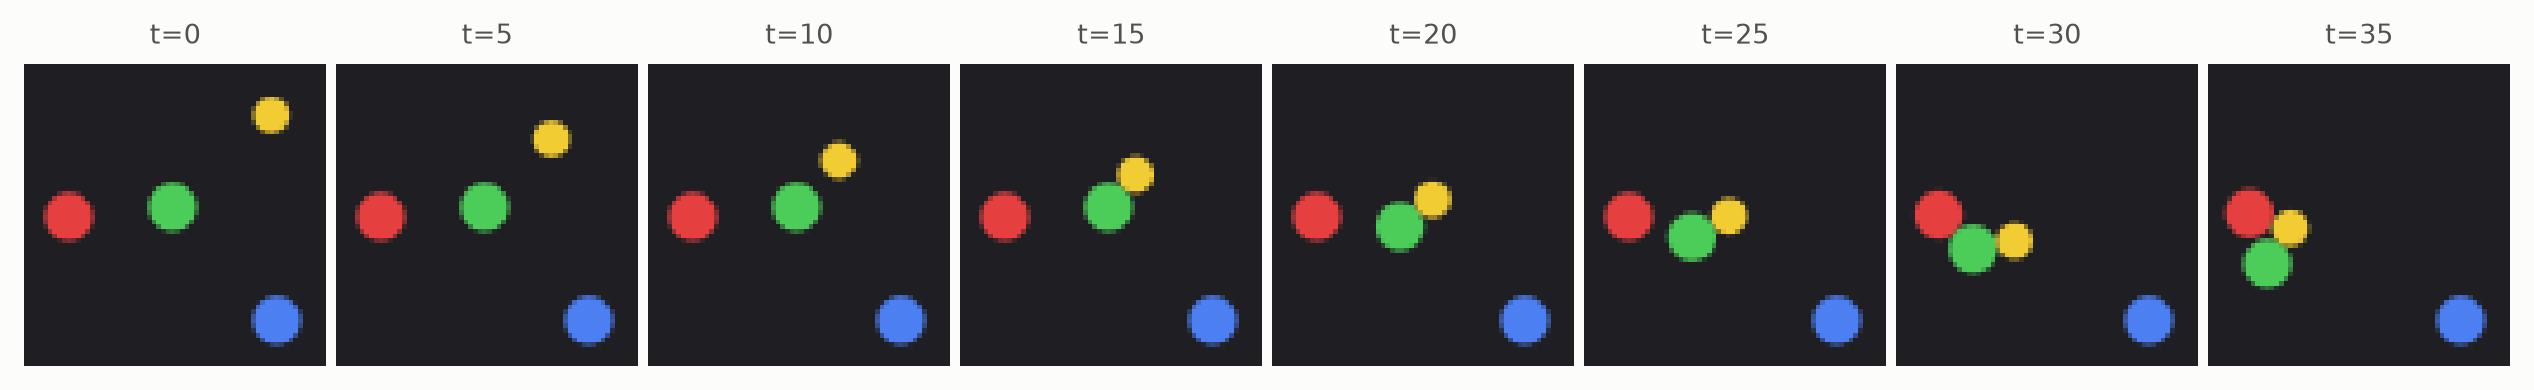

In [4]:
env = Blocks(batch_size=1024, device=device)
data = env.collect(50, generator=torch.Generator().manual_seed(0))
plots.images(data["pixels"][0, :40:5].cpu(), [f"t={t}" for t in range(0, 40, 5)], size=1.3)

### Objects first: a frozen slot encoder
C-JEPA works on the slots of an object-centric encoder trained beforehand and then frozen (VideoSAUR on DINOv2 features in the paper). Here a small slot-attention autoencoder learns five slots by reconstructing the frames: four objects and the background. Its learned initial slots split the image by region, not by color, so within an episode the slots of each frame are reordered to best match the previous frame's: a slot then follows its object.

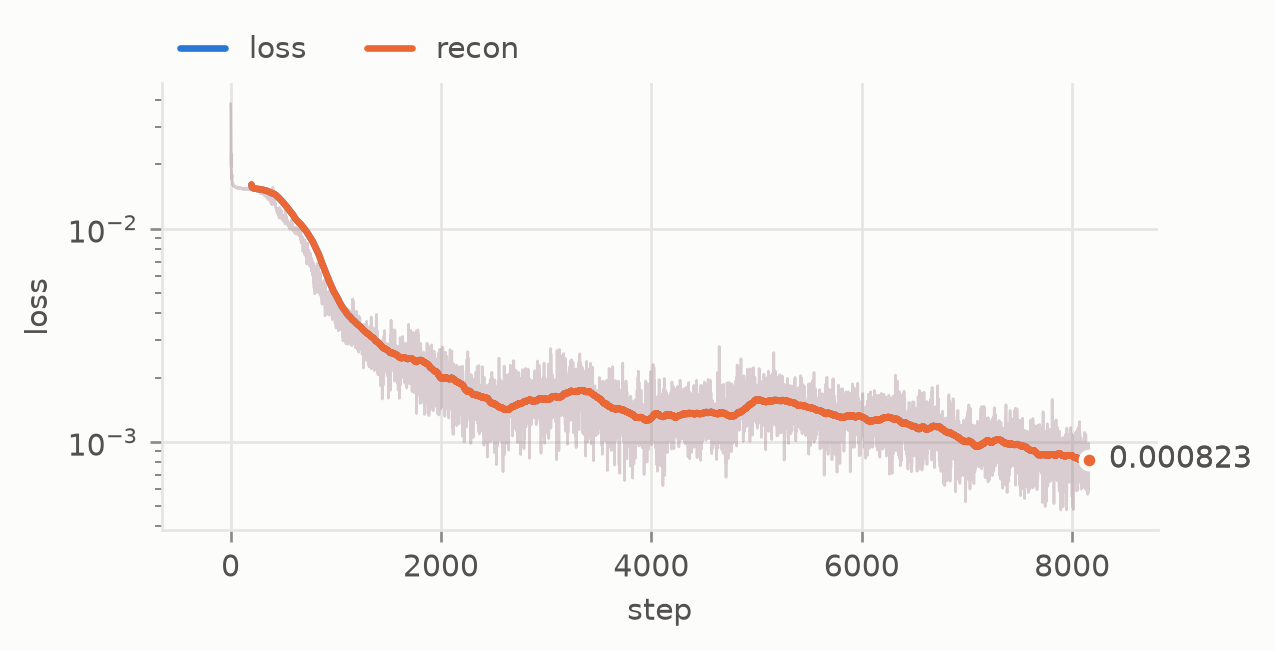

In [5]:
slot_encoder = SlotEncoder(img_size=64, num_slots=5, slot_dim=64).to(device)
frames = DataLoader(TensorDataset(data["pixels"].flatten(0, 1)), batch_size=64, shuffle=True, drop_last=True)
slot_log = fit(slot_encoder, frames, epochs=10, lr=4e-4, clip=1.0, inputs=lambda b: (b[0], True))
plots.curves(slot_log, smooth=200)

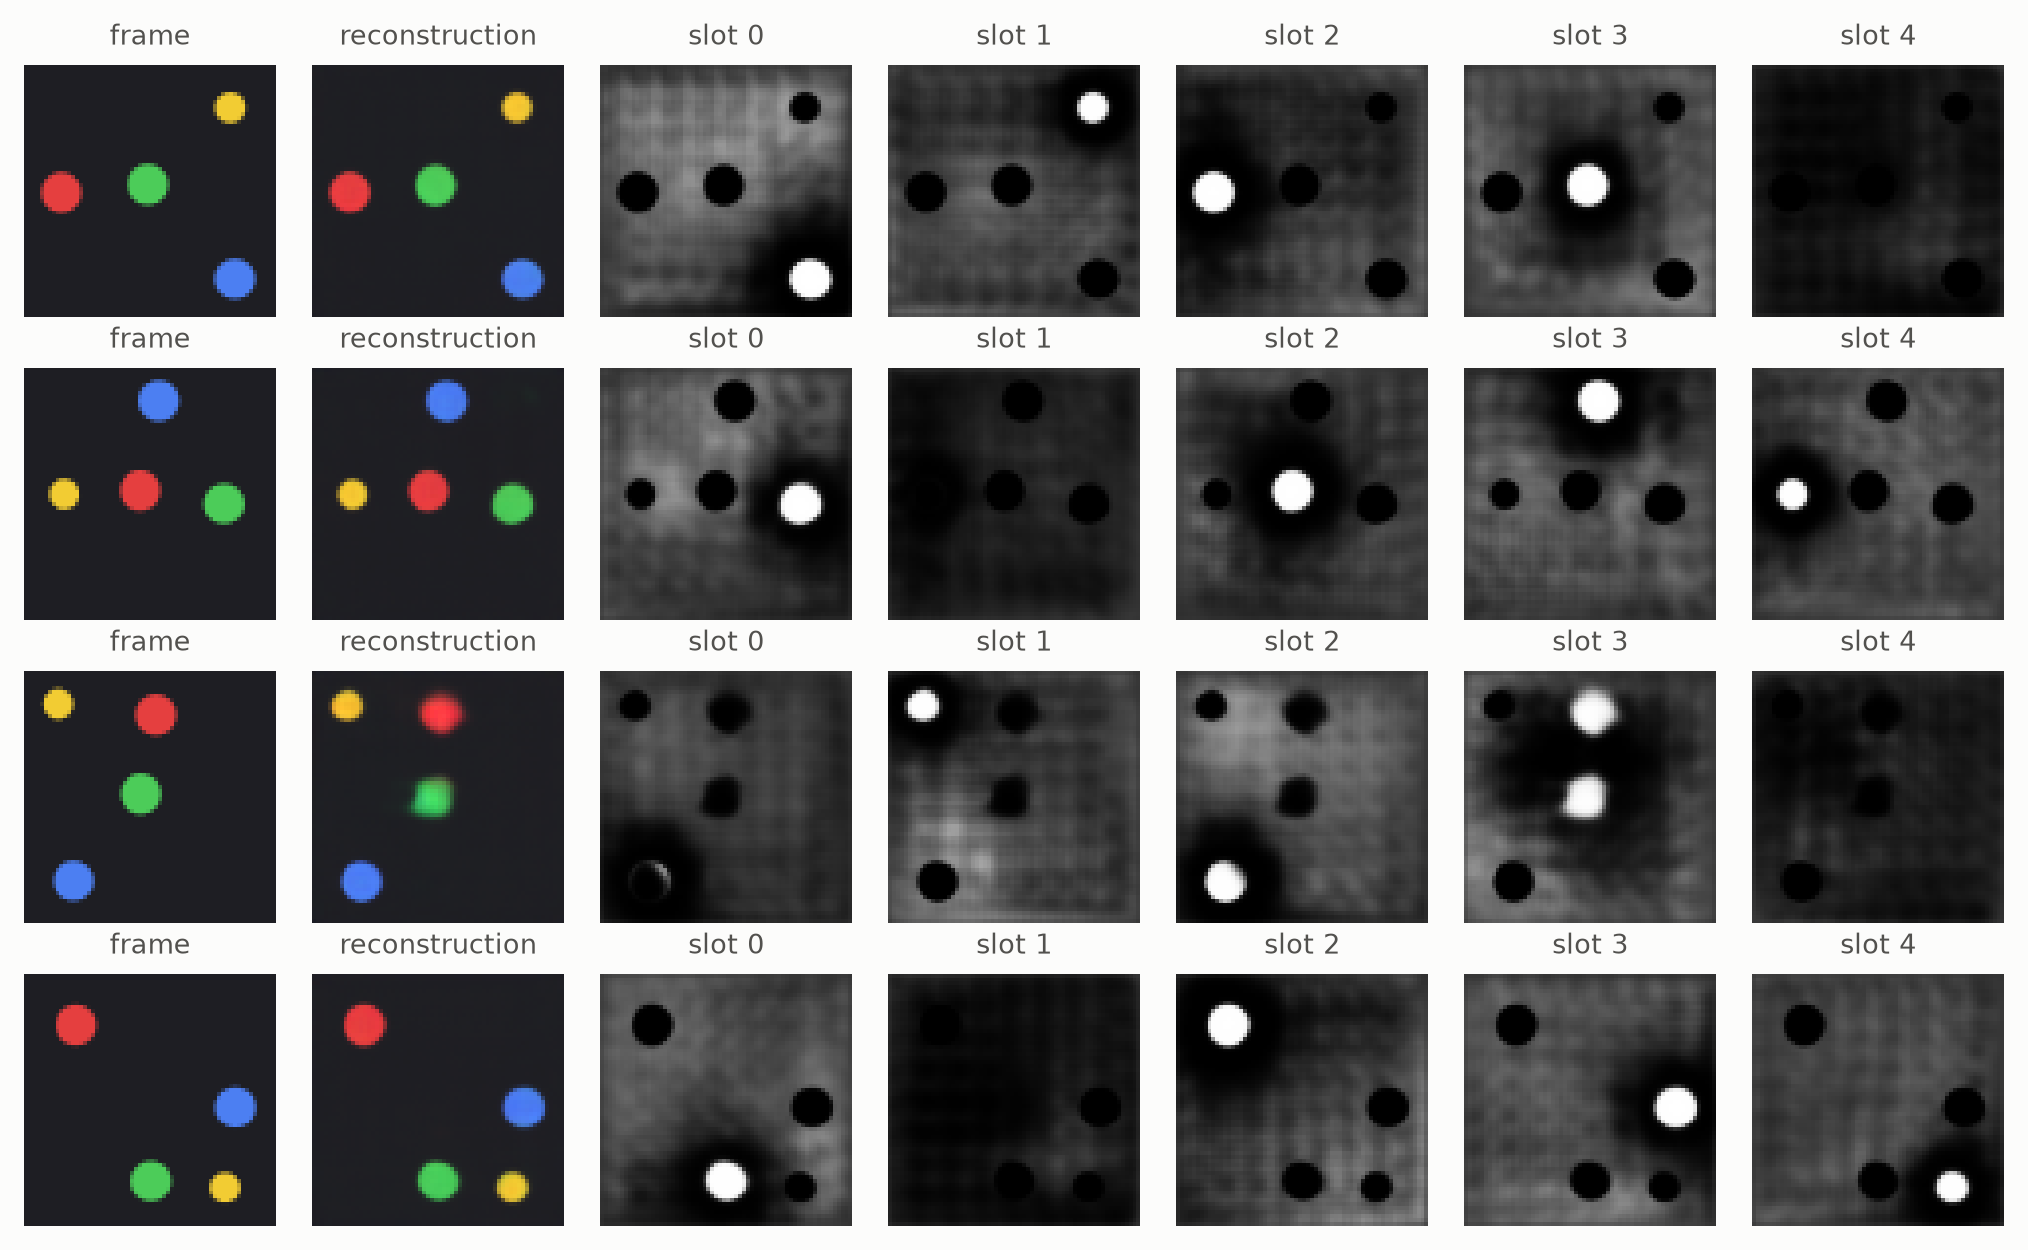

In [6]:
with torch.no_grad():
    out = slot_encoder(data["pixels"][:4, 0], reconstruct=True)
panels = torch.cat([data["pixels"][:4, 0, None], out["recon"][:, None], out["masks"].expand(-1, -1, 3, -1, -1)], 1)
plots.images(panels.flatten(0, 1).clamp(0, 1).cpu(), (["frame", "reconstruction"] + [f"slot {s}" for s in range(5)]) * 4, ncols=7, size=1.2)

The world models train on the frozen slots, extracted once for the whole dataset, as the paper does. C-JEPA hides up to two objects per sample (the paper's Push-T setting); OC-JEPA is the same model trained with no hidden objects, the paper's ablation. LeWM, with one embedding per frame learned end to end from pixels, is the object-free baseline.

In [7]:
def encode_slots(pixels):
    """Slots of whole episodes ``(N, T, 5, 64)``, each frame's slots matched to the previous frame's."""
    with torch.no_grad():
        return torch.cat([slot_encoder(p) for p in pixels.split(256)])

data["slots"] = encode_slots(data["pixels"])

def causal_jepa(max_masked):
    return CausalJEPA(slot_encoder, action_dim=2 * SKIP, slot_dim=64, history=3, max_masked=max_masked, depth=6, num_heads=8, head_dim=32, mlp_dim=512).to(device)

cjepa, ocjepa = causal_jepa(max_masked=2), causal_jepa(max_masked=0)
lewm = LeWM(CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4), action_dim=2 * SKIP, embed_dim=128, history=3, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512).to(device)
for name, model in {"C-JEPA": cjepa, "LeWM": lewm}.items():
    print(f"{name}: {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f}M trained parameters")

C-JEPA: 0.81M trained parameters
LeWM: 2.34M trained parameters


## Train
C-JEPA regresses the hidden objects' slots in the history and every slot of the next step; OC-JEPA only the next step. LeWM trains its encoder and predictor together with SIGReg.

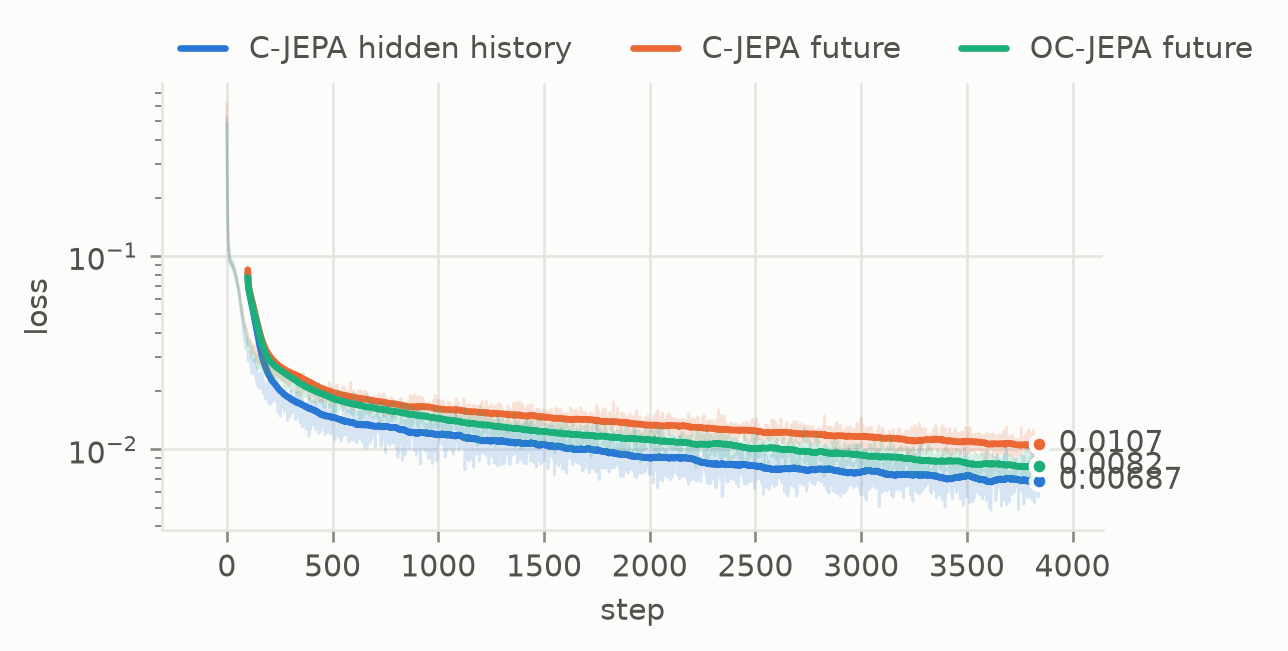

In [8]:
slot_windows = DataLoader(TrajectoryDataset({"slots": data["slots"], "actions": data["actions"]}, window=4, frameskip=SKIP), batch_size=256, shuffle=True, drop_last=True)
log = fit(cjepa, slot_windows, epochs=30, lr=5e-4, inputs=lambda b: (b["slots"], b["actions"]))
oc_log = fit(ocjepa, slot_windows, epochs=30, lr=5e-4, inputs=lambda b: (b["slots"], b["actions"]))
plots.curves({"C-JEPA hidden history": log["history"], "C-JEPA future": log["future"], "OC-JEPA future": oc_log["future"]}, smooth=100)

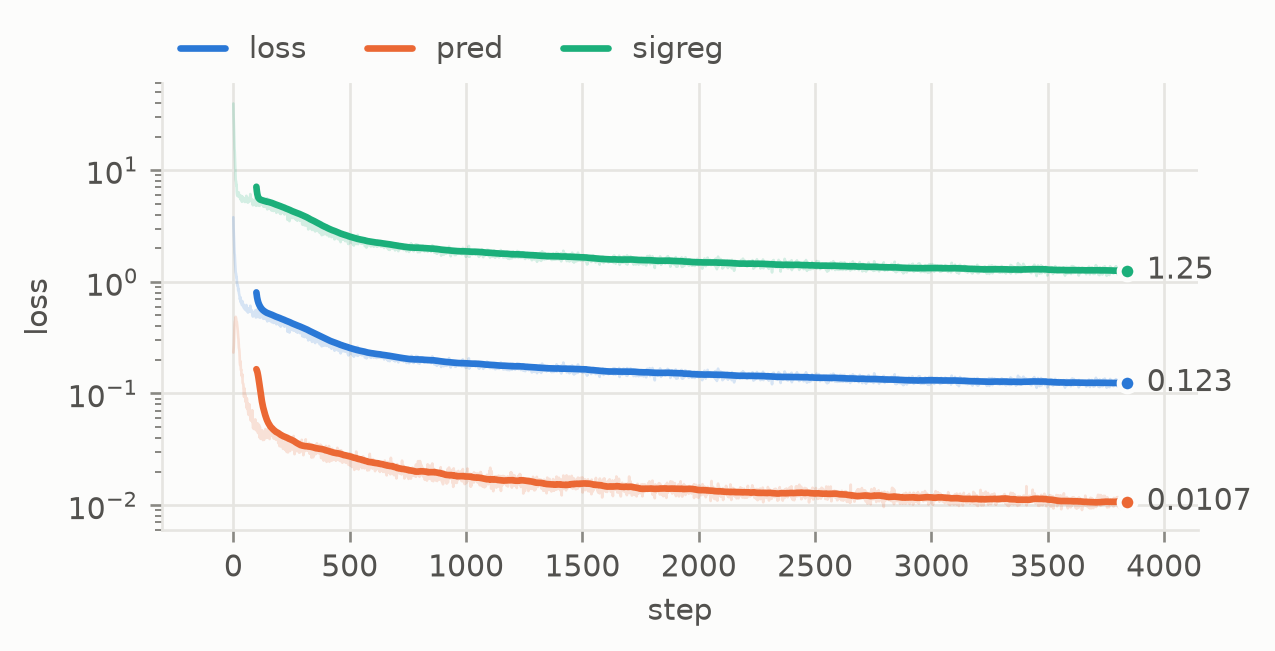

In [9]:
pixel_windows = DataLoader(TrajectoryDataset({"pixels": data["pixels"], "actions": data["actions"]}, window=4, frameskip=SKIP), batch_size=128, shuffle=True, drop_last=True)
lewm_log = fit(lewm, pixel_windows, epochs=15, lr=5e-4)
plots.curves(lewm_log, smooth=100)

## Hide a disc, ask where it went
Take three steps of a held-out episode in which the agent pushes a disc, and hide that disc's slot after the first step. The predictor sees only its first-step slot (the identity anchor), the other objects and the actions. A linear probe, fit on real frames, reads positions from slots. Copying the first step is what a model that ignores interactions would answer.

In [10]:
test = Blocks(batch_size=256, device=device).collect(50, generator=torch.Generator().manual_seed(1))
probe_set = Blocks(batch_size=256, device=device).collect(50, generator=torch.Generator().manual_seed(2))
test["slots"], probe_set["slots"] = encode_slots(test["pixels"]), encode_slots(probe_set["pixels"])

def owners(slots, states):
    """Index of the slot that holds each object ``(N, 4)``: the one whose decoded mask covers the object's center."""
    out = []
    with torch.no_grad():
        for z, s in zip(slots.split(256), states.split(256)):
            masks = slot_encoder.decode(z)[1][:, :, 0]  # (n, S, H, W)
            xy = (s.view(-1, 4, 2) * 64).long().clamp(0, 63)
            out.append(masks[torch.arange(len(z))[:, None], :, xy[..., 1], xy[..., 0]].argmax(-1))
    return torch.cat(out)

def probe(train_x, train_y):
    """Linear map from features to positions, fit on the probe episodes."""
    return lambda x: metrics.linear_probe(train_x, train_y, x, x.new_zeros(len(x), train_y.size(1))).predictions

def object_slots(slots, own):
    """The slot of each object, ``(N, S, D)`` and ``(N, 4)`` to ``(N, 4, D)``."""
    return slots[torch.arange(len(slots))[:, None], own]

# one probe for every object, from the slot that holds it, and one from LeWM's embedding to all eight coordinates
slots, states = probe_set["slots"][:, ::2].flatten(0, 1), probe_set["states"][:, ::2].flatten(0, 1)
slot_probe = probe(object_slots(slots, owners(slots, states)).flatten(0, 1), states.view(-1, 2))
with torch.no_grad():
    lewm_probe = probe(torch.cat([lewm.encode(p) for p in probe_set["pixels"][:, ::2].split(64)]).flatten(0, 1), states)
    slots, states = test["slots"][:, ::5].flatten(0, 1), test["states"][:, ::5].flatten(0, 1)
    real_slots = slot_probe(object_slots(slots, owners(slots, states)).flatten(0, 1)).view(-1, 8)
    real_lewm = lewm_probe(torch.cat([lewm.encode(p) for p in test["pixels"][:, ::5].split(64)]).flatten(0, 1))
print(f"probes on held-out real frames: slots R² {metrics.r2_score(real_slots, states):.3f} ({64 * (real_slots - states).view(-1, 4, 2).norm(dim=-1).mean():.2f} px), LeWM R² {metrics.r2_score(real_lewm, states):.3f} ({64 * (real_lewm - states).view(-1, 4, 2).norm(dim=-1).mean():.2f} px)")

probes on held-out real frames: slots R² 0.974 (1.68 px), LeWM R² 0.738 (6.61 px)


## Hide a disc, ask where it went
Take three steps of a held-out episode in which the agent pushes a disc, and hide that disc's slot after the first step. The predictor sees only its first-step slot (the identity anchor), the other objects and the actions. The probe reads the disc's position at the third step from the slot the model fills in. Copying the first step is what a model that ignores interactions would answer.

In [11]:
starts = range(0, 50 - 3 * SKIP + 1, SKIP)
z = torch.cat([test["slots"][:, t : t + 3 * SKIP : SKIP] for t in starts])  # (N, 3, S, D)
a = torch.cat([test["actions"][:, t : t + 3 * SKIP].reshape(-1, 3, 2 * SKIP) for t in starts])
s = torch.cat([test["states"][:, t : t + 3 * SKIP : SKIP] for t in starts])  # (N, 3, 8)
n = torch.arange(len(z))
with torch.no_grad():
    move = (env.blocks(s[:, 2]) - env.blocks(s[:, 0])).norm(dim=-1)  # (N, 3)
    disc = move.argmax(1)  # the disc that moved most
    keep = move.amax(1) > 0.05  # pushed by at least 3 pixels
    slot = owners(z[:, 0], s[:, 0])[n, disc + 1]
    hidden = torch.nn.functional.one_hot(slot, 5).bool()
    truth = env.blocks(s[:, 2])[n, disc]
    filled = {"copy first step": z[n, 0, slot]}
    for name, model in {"C-JEPA": cjepa, "OC-JEPA (never trained to)": ocjepa}.items():
        filled[name] = model.predict(z, a, masked=hidden)[n, 2, slot]
    fill_error = {name: 64 * (slot_probe(x) - truth).norm(dim=-1)[keep].mean().item() for name, x in filled.items()}
print(f"{keep.sum().item()} windows where a disc moved by more than 3 pixels")
for name, e in fill_error.items():
    print(f"  {name:28s} hidden disc off by {e:.2f} px")

500 windows where a disc moved by more than 3 pixels
  copy first step              hidden disc off by 7.91 px
  C-JEPA                       hidden disc off by 6.48 px
  OC-JEPA (never trained to)   hidden disc off by 16.25 px


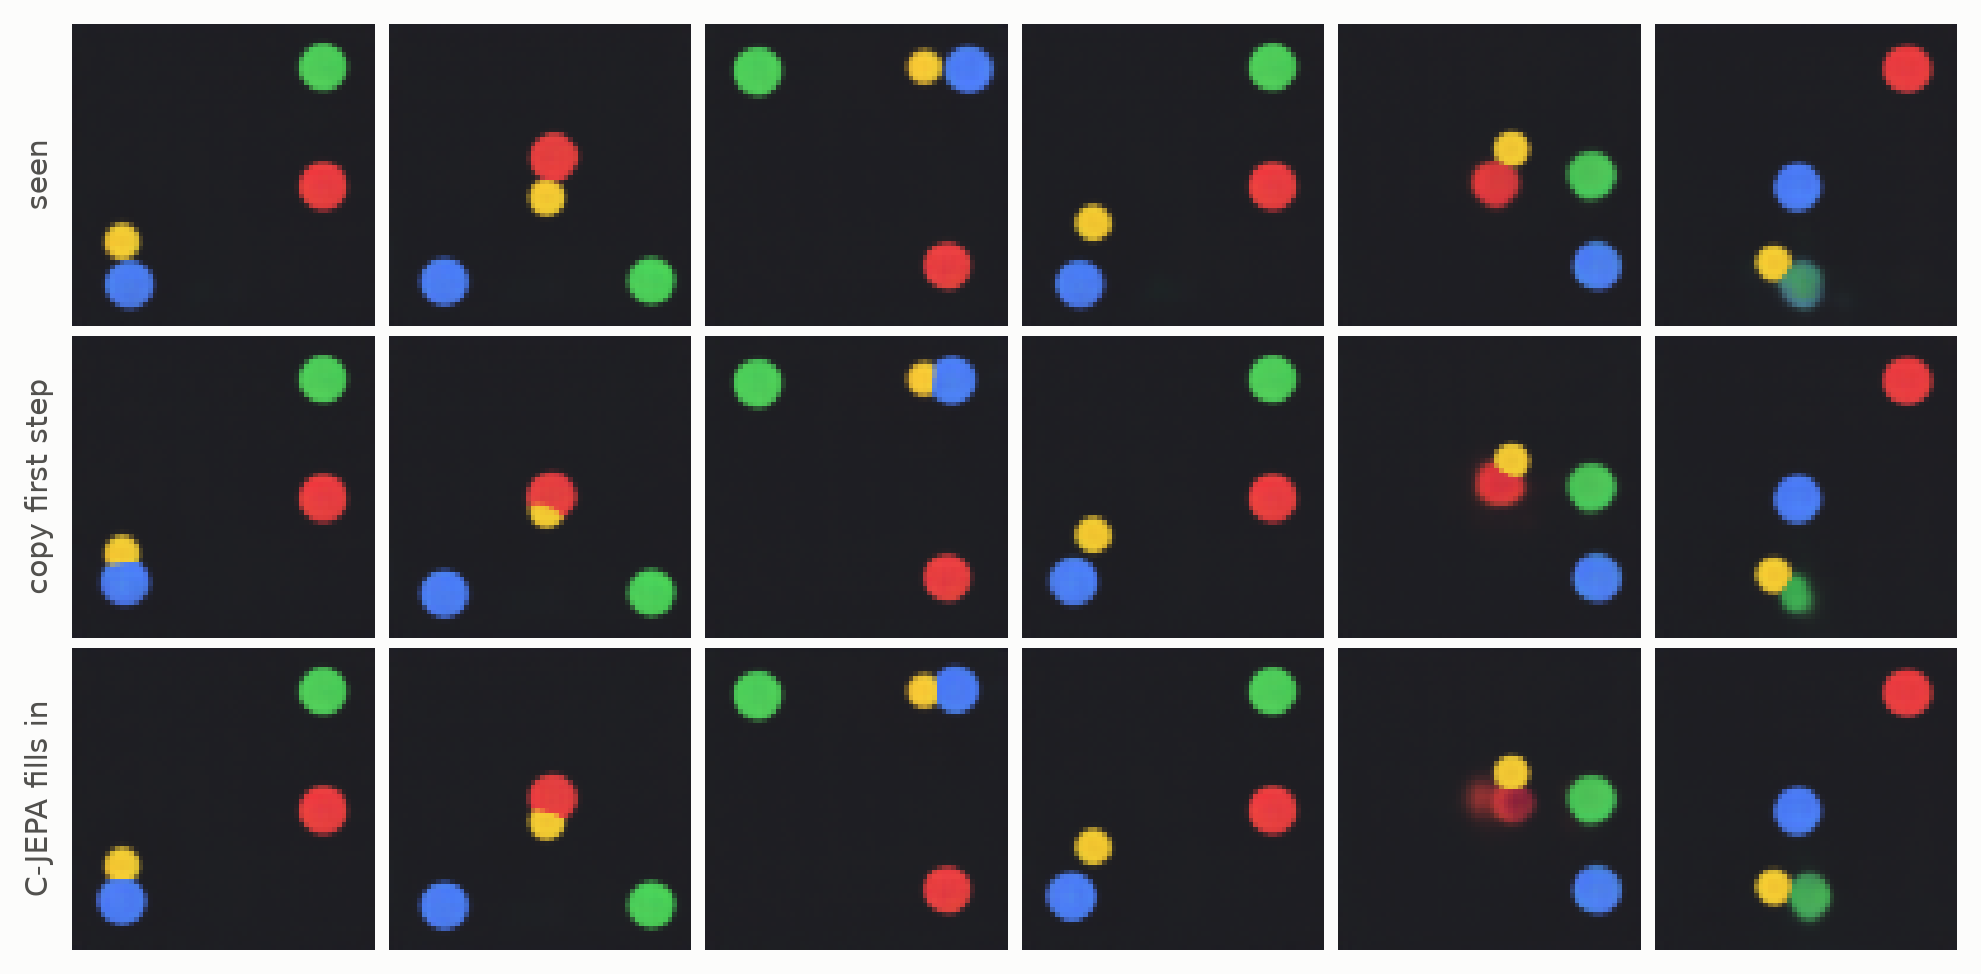

In [12]:
with torch.no_grad():
    show = keep.nonzero()[:6, 0]
    frames = [z[show, 2]]
    for name in ("copy first step", "C-JEPA"):
        frames.append(z[show, 2].clone())
        frames[-1][torch.arange(len(show)), slot[show]] = filled[name][show]
    pictures = torch.stack([slot_encoder.decode(f)[0] for f in frames])  # (3, 6, 3, H, W)
plots.images(pictures.flatten(0, 1).clamp(0, 1).cpu(), ncols=6, size=1.3, rows=["seen", "copy first step", "C-JEPA fills in"])

## Imagined futures, object by object
From one frame and the next 20 actions (4 steps), each model imagines where every object ends up, and the probes read the positions. A pushed disc is where interactions matter; a disc nobody touches only has to stay put.

In [13]:
starts = range(0, 50 - 4 * SKIP + 1, SKIP)
frames = torch.cat([test["pixels"][:, t] for t in starts])
plan = torch.cat([test["actions"][:, t : t + 4 * SKIP].reshape(-1, 4, 2 * SKIP) for t in starts])
first = torch.cat([test["states"][:, t] for t in starts])
last = torch.cat([test["states"][:, t + 4 * SKIP] for t in starts])
with torch.no_grad():
    z0 = torch.cat([slot_encoder(f) for f in frames.split(256)])  # slots of single frames
    own = owners(z0, first)  # the predictor keeps slot order, so each object stays in its slot
    guesses = {"no change": slot_probe(object_slots(z0, own).flatten(0, 1)).view(-1, 8)}
    for name, model in {"C-JEPA": cjepa, "OC-JEPA": ocjepa}.items():
        final = torch.cat([model.rollout(z[:, None], p)[:, -1] for z, p in zip(z0.split(256), plan.split(256))])
        guesses[name] = slot_probe(object_slots(final, own).flatten(0, 1)).view(-1, 8)
    guesses["LeWM"] = lewm_probe(torch.cat([lewm.rollout(lewm.encode(f[:, None]), p)[:, -1] for f, p in zip(frames.split(256), plan.split(256))]))
pushed = (env.blocks(last) - env.blocks(first)).norm(dim=-1) > 0.02  # (N, 3)
errors = {}
for name, g in guesses.items():
    e = 64 * (env.blocks(g) - env.blocks(last)).norm(dim=-1)
    errors[name] = {"pushed discs": e[pushed].mean().item(), "untouched discs": e[~pushed].mean().item(), "agent": 64 * (g[:, :2] - last[:, :2]).norm(dim=-1).mean().item()}
    print(f"{name:10s} " + "   ".join(f"{k} {v:.2f} px" for k, v in errors[name].items()))
print(f"{pushed.float().mean():.0%} of the discs are pushed within the 20 steps")

no change  pushed discs 8.43 px   untouched discs 2.13 px   agent 15.78 px
C-JEPA     pushed discs 7.28 px   untouched discs 3.76 px   agent 5.21 px
OC-JEPA    pushed discs 8.49 px   untouched discs 4.16 px   agent 4.03 px
LeWM       pushed discs 8.83 px   untouched discs 5.53 px   agent 15.60 px
19% of the discs are pushed within the 20 steps


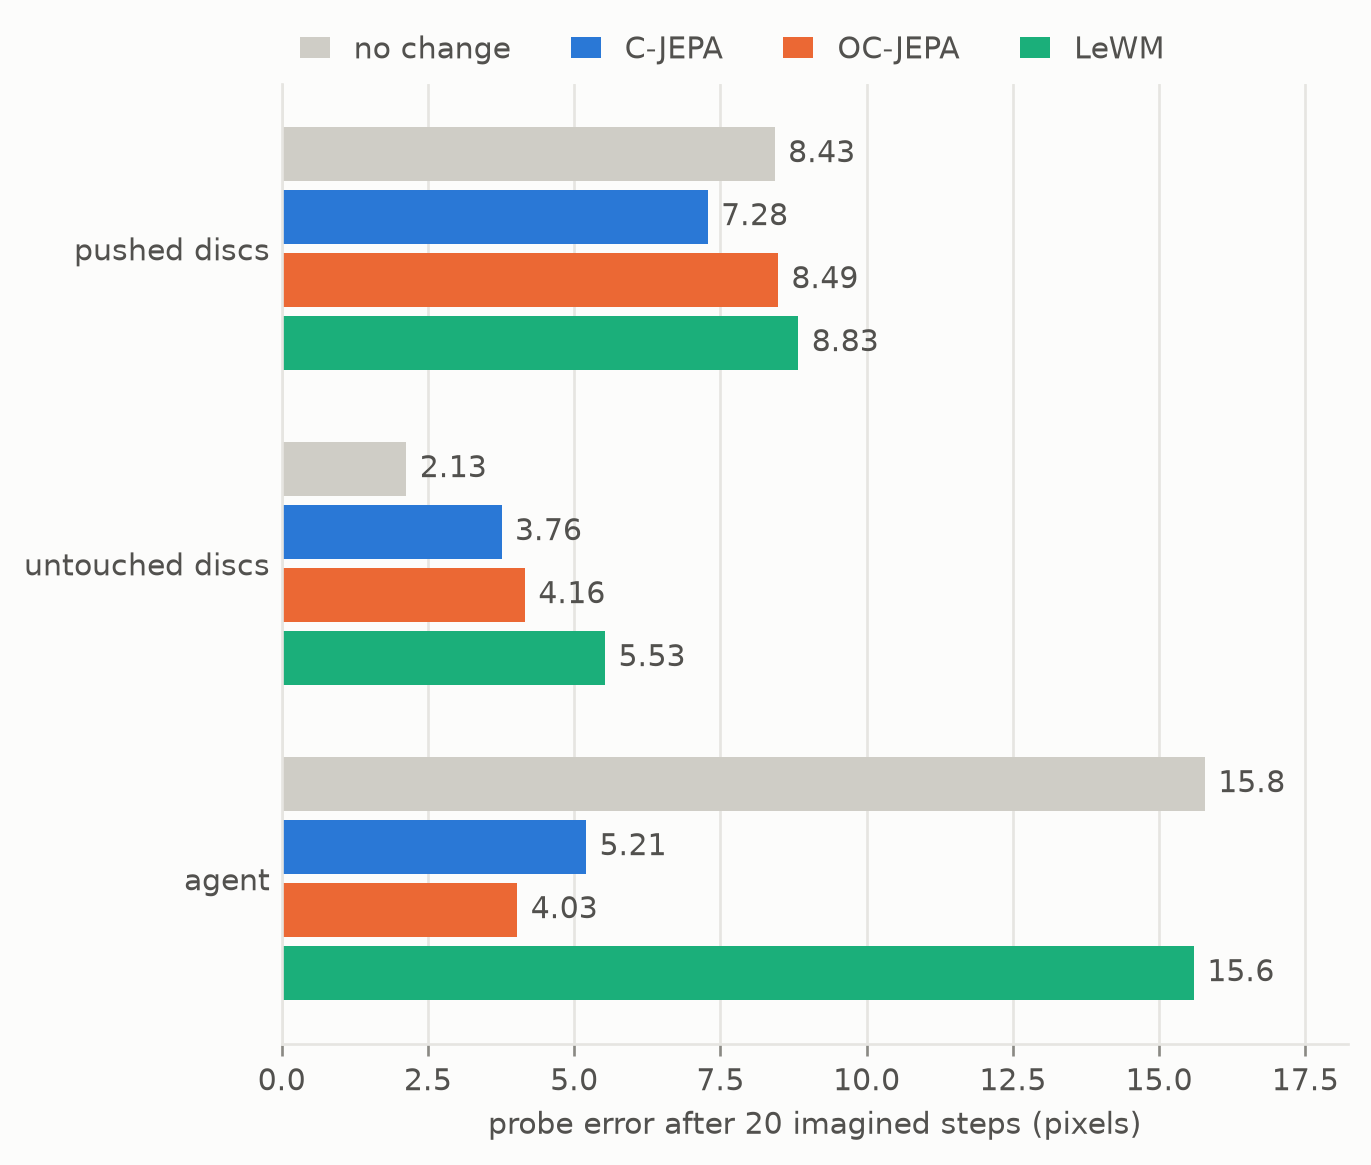

In [14]:
plots.bars({k: {name: errors[name][k] for name in errors} for k in ("pushed discs", "untouched discs", "agent")}, xlabel="probe error after 20 imagined steps (pixels)", baseline="no change")

## Plan a push
Each task starts with the agent against a disc; the goal image is the scene 15 steps later, after the agent pushed that disc (and whatever it ran into) by at least 6 pixels. An episode succeeds when every disc is within 4 pixels of its place in the goal at some step within 30 steps. CEM searches 4 chunks of 5 actions and the policy runs the first chunk before planning again. C-JEPA's cost matches the predicted slots to the goal's slots first, as in the paper.

In [15]:
env = Blocks(batch_size=64, device=device)
start, goal = env.tasks(generator=torch.Generator().manual_seed(3))
goal_images = env.render(goal)

planner = CEM(horizon=4, action_dim=2 * SKIP, num_samples=300, num_elites=30, bounds=(-1, 1))
policies = {
    "C-JEPA + CEM": evaluation.goal_policy(cjepa, planner, goal_images, action_dim=2),
    "OC-JEPA + CEM": evaluation.goal_policy(ocjepa, planner, goal_images, action_dim=2),
    "LeWM + CEM": evaluation.goal_policy(lewm, planner, goal_images, action_dim=2),
    "random actions": evaluation.random_policy(env),
}
result = evaluation.goal_reaching(env, policies, start, goal, steps=30, success="reached")
result

                          success  reached   steps  final distance  progress  smoothness  ms / step
C-JEPA + CEM         6% [2%, 15%]       6%      10           0.167     0.252       0.706   4.46e+03
OC-JEPA + CEM        8% [3%, 17%]       8%    17.2           0.189     0.174       0.793   4.46e+03
LeWM + CEM           9% [4%, 19%]       9%    15.2           0.198    0.0775       0.486   1.07e+03
random actions        0% [0%, 6%]       0%     nan           0.227    0.0465        1.06     0.0342

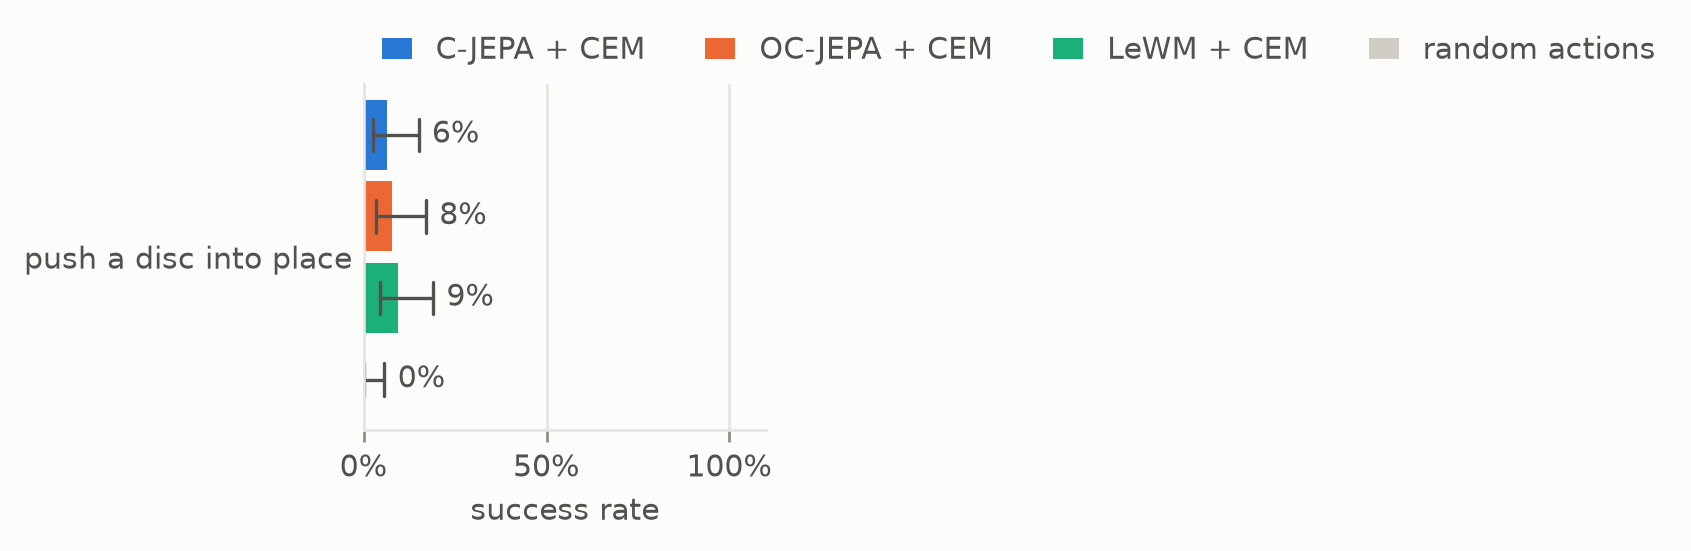

In [16]:
plots.bars({"push a disc into place": result.intervals()}, xlabel="success rate", baseline="random actions")

## Summary
On this scene, object-level masking does what the paper says it should, at small scale. Given only the other objects and the actions, C-JEPA places a hidden, pushed disc 6.5 px from where it really is. Copying its first step is off by 7.9 px, and OC-JEPA, which never learned to fill in, by 16.3 px. Over 20 imagined steps C-JEPA places pushed discs best: 7.3 px, against 8.5 for OC-JEPA, 8.4 for assuming nothing moves and 8.8 for LeWM. No model beats "no change" on discs nobody touches (C-JEPA 3.8 px against 2.1), and OC-JEPA follows the agent a little better (4.0 against 5.2 px).

Planning shows no difference. All three models succeed on 6 to 9% of the push tasks, with overlapping intervals; random actions succeed on none. C-JEPA closes the most distance to the goal (median progress 25%, against 17% for OC-JEPA and 8% for LeWM), but rarely ends within 4 pixels on every disc. The likely reasons: training is short (the losses are still falling after 30 epochs), the tolerance is tight, and CEM with a terminal cost and 300 samples rarely finds a push that ends at the right spot. The paper's planning gain on Push-T (88.7% against 76.0% for OC-JEPA) is not reproduced here.